In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

## A(i):

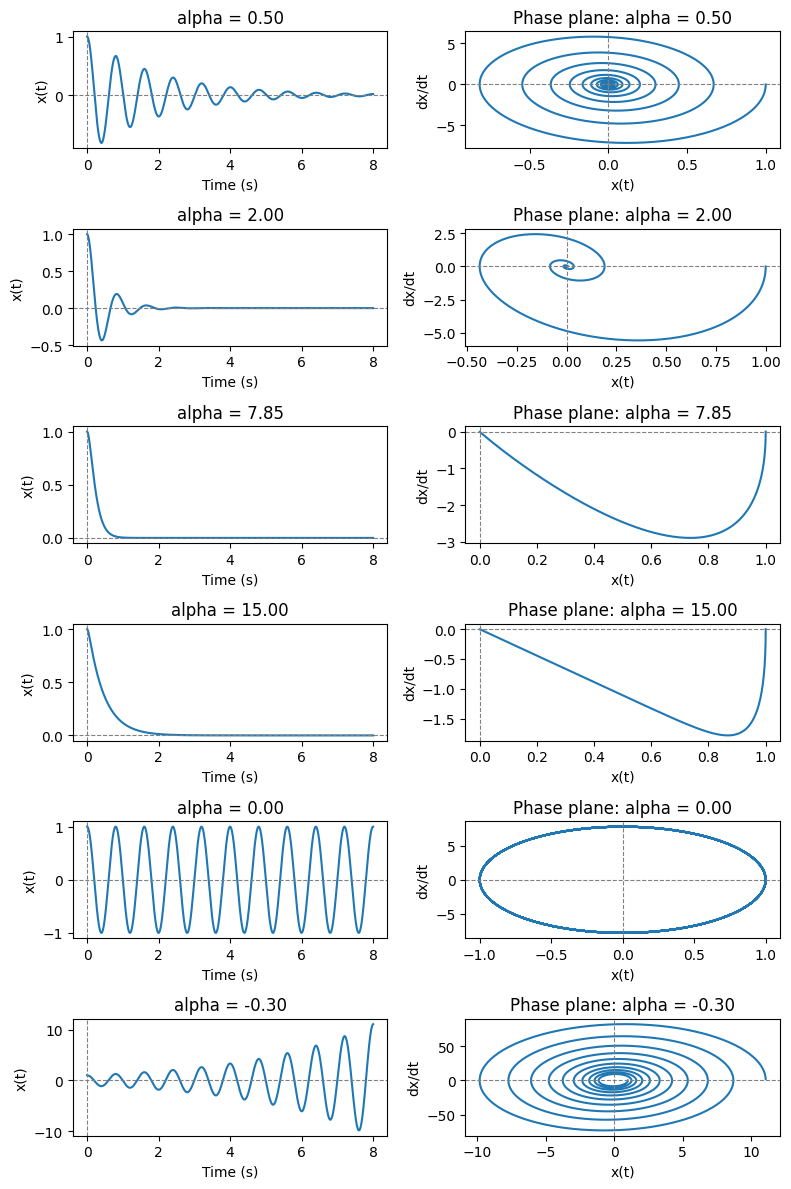

In [7]:
# Natural frequency = 0.8 seconds
freq = 2 * np.pi / 0.8

# Differential equation: dx/dt = v, dv/dt = -2av-w^2x
def oscillator(t, state, alpha):
    x, velocity = state

    dx_dt = velocity
    dv_dt = -2 * alpha * velocity - freq**2 * x

    return [dx_dt, dv_dt]

alphas = [0.5, 2, freq, 15, 0, -0.3]

# Simulate 8 seconds
t = np.linspace(0, 8, 2000)

fig, axes = plt.subplots(6, 2, figsize=(8, 12))

for i, alpha in enumerate(alphas):
    solution = solve_ivp(
        oscillator,
        (0, 8),
        [1, 0],
        t_eval=t,
        args=(alpha,)
    )

    x = solution.y[0]
    velocity = solution.y[1]

    # Time-domain plot
    axes[i, 0].plot(t, x)
    axes[i, 0].axhline(0, color='gray', linestyle='--', linewidth=0.8)
    axes[i, 0].axvline(0, color='gray', linestyle='--', linewidth=0.8)
    axes[i, 0].set_title(f"alpha = {alpha:.2f}")
    axes[i, 0].set_xlabel("Time (s)")
    axes[i, 0].set_ylabel("x(t)")

    # Phase-plane plot
    axes[i, 1].plot(x, velocity)
    axes[i, 1].axhline(0, color='gray', linestyle='--', linewidth=0.8)
    axes[i, 1].axvline(0, color='gray', linestyle='--', linewidth=0.8)
    axes[i, 1].set_title(f"Phase plane: alpha = {alpha:.2f}")
    axes[i, 1].set_xlabel("x(t)")
    axes[i, 1].set_ylabel("dx/dt")

plt.tight_layout()
plt.show()

## A(ii):

alpha = 0.5, x(0) = 0.1
Amplitude = 2.011
Period = 0.800 s

alpha = 0.5, x(0) = 4
Amplitude = 2.012
Period = 0.800 s

alpha = 5, x(0) = 0.1
Amplitude = 2.023
Period = 0.877 s

alpha = 5, x(0) = 4
Amplitude = 2.021
Period = 0.876 s

alpha = 20, x(0) = 0.1
Amplitude = 2.023
Period = 1.493 s

alpha = 20, x(0) = 4
Amplitude = 2.027
Period = 1.494 s



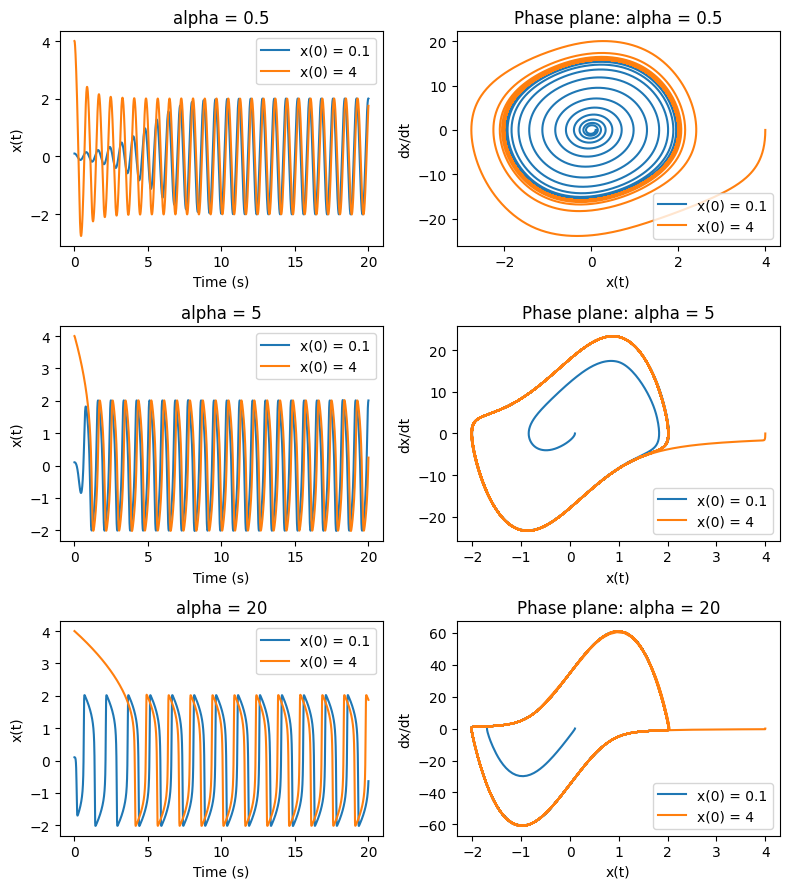

In [10]:
# Natural frequency
freq = 2 * np.pi / 0.8

# Van der Pol equation
def van_der_pol(t, state, alpha):
    x, velocity = state

    dx_dt = velocity
    dv_dt = 2 * alpha * (1 - x**2) * velocity - freq**2 * x

    return [dx_dt, dv_dt]

alphas = [0.5, 5, 20]
initial_positions = [0.1, 4]

# Simulate 20 seconds
t = np.linspace(0, 20, 8000)

fig, axes = plt.subplots(3, 2, figsize=(8, 9))

for i, alpha in enumerate(alphas):

    for x0 in initial_positions:

        solution = solve_ivp(
            van_der_pol,
            (0, 20),
            [x0, 0],
            t_eval=t,
            args=(alpha,)
        )

        x = solution.y[0]
        velocity = solution.y[1]

        # Time-domain plot
        axes[i, 0].plot(t, x, label=f"x(0) = {x0}")
        axes[i, 0].set_title(f"alpha = {alpha}")
        axes[i, 0].set_xlabel("Time (s)")
        axes[i, 0].set_ylabel("x(t)")
        axes[i, 0].legend()

        # Phase-plane plot
        axes[i, 1].plot(x, velocity, label=f"x(0) = {x0}")
        axes[i, 1].set_title(f"Phase plane: alpha = {alpha}")
        axes[i, 1].set_xlabel("x(t)")
        axes[i, 1].set_ylabel("dx/dt")
        axes[i, 1].legend()

        # Find steady amplitude and period
        steady = t >= 10
        x_steady = x[steady]
        t_steady = t[steady]

        amplitude = (max(x_steady) - min(x_steady)) / 2

        peaks, _ = find_peaks(x_steady)
        period = np.mean(np.diff(t_steady[peaks]))

        print(f"alpha = {alpha}, x(0) = {x0}")
        print(f"Amplitude = {amplitude:.3f}")
        print(f"Period = {period:.3f} s\n")

plt.tight_layout()
plt.show()

## A(iii)

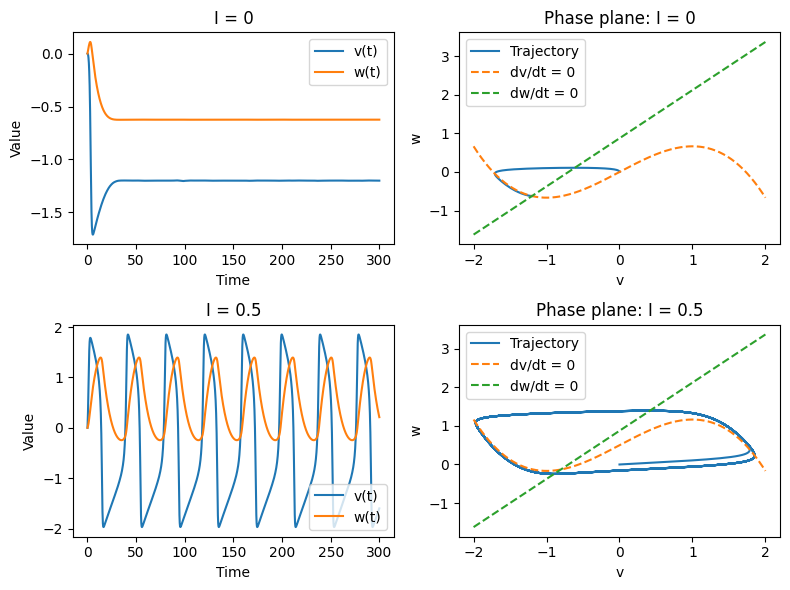

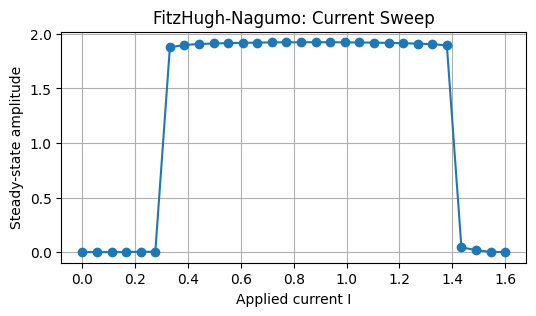

In [ ]:
a = 0.7
b = 0.8
epsilon = 0.08

# FitzHugh-Nagumo equations
def fitzhugh_nagumo(t, state, I):
    v, w = state

    dv_dt = v - v**3 / 3 - w + I
    dw_dt = epsilon * (v + a - b * w)

    return [dv_dt, dw_dt]

# I = 0 and I = 0.5
currents = [0, 0.5]

t = np.linspace(0, 300, 3000)

fig, axes = plt.subplots(2, 2, figsize=(8, 6))

for i, I in enumerate(currents):

    solution = solve_ivp(
        fitzhugh_nagumo,
        (0, 300),
        [0, 0],
        t_eval=t,
        args=(I,)
    )

    v = solution.y[0]
    w = solution.y[1]

    # Time-domain plot
    axes[i, 0].plot(t, v, label="v(t)")
    axes[i, 0].plot(t, w, label="w(t)")
    axes[i, 0].set_title(f"I = {I}")
    axes[i, 0].set_xlabel("Time")
    axes[i, 0].set_ylabel("Value")
    axes[i, 0].legend()

    # Nullclines
    v_range = np.linspace(-2, 2, 300)

    # dv/dt = 0
    nullcline_v = v_range - v_range**3 / 3 + I

    # dw/dt = 0
    nullcline_w = (v_range + a) / b

    # Phase-plane plot
    axes[i, 1].plot(v, w, label="Trajectory")
    axes[i, 1].plot(v_range, nullcline_v, "--", label="dv/dt = 0")
    axes[i, 1].plot(v_range, nullcline_w, "--", label="dw/dt = 0")

    axes[i, 1].set_title(f"Phase plane: I = {I}")
    axes[i, 1].set_xlabel("v")
    axes[i, 1].set_ylabel("w")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()


# Sweep I from 0 to 1.6
I_values = np.linspace(0, 1.6, 30)
amplitudes = []

for I in I_values:
    solution = solve_ivp(
        fitzhugh_nagumo,
        (0, 300),
        [0, 0],
        t_eval=t,
        args=(I,)
    )

    v = solution.y[0]

    # Use the final 100 time
    steady = t >= 200
    v_steady = v[steady]

    # Measure voltage amplitude
    amplitude = (max(v_steady) - min(v_steady)) / 2
    amplitudes.append(amplitude)

# Plot amplitude vs applied current
plt.figure(figsize=(6, 3))
plt.plot(I_values, amplitudes, marker="o")
plt.xlabel("Applied current I")
plt.ylabel("Steady-state amplitude")
plt.title("FitzHugh-Nagumo: Current Sweep")
plt.grid()
plt.show()



## B(i)

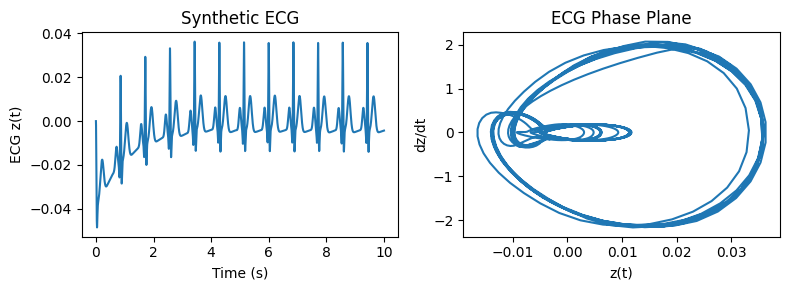

In [4]:
# Heart rate = 70 beats
omega = 2 * np.pi * 70 / 60

# Original McSharry-Clifford parameters (P, Q, R, S, T)
theta_i = np.array([-np.pi/3, -np.pi/12, 0, np.pi/12, np.pi/2])
a_i = np.array([1.2, -5, 30, -7.5, 0.75])
b_i = np.array([0.25, 0.1, 0.1, 0.1, 0.4])

# Differential equations
def ecg_model(t, state):
    x, y, z = state

    rho = 1 - np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)

    # Angular difference, wrapped to [-pi, pi]
    dtheta = (theta - theta_i + np.pi) % (2 * np.pi) - np.pi

    # ECG baseline
    z0 = 0

    dx_dt = rho * x - omega * y
    dy_dt = rho * y + omega * x

    dz_dt = -np.sum(a_i * dtheta * np.exp(-dtheta**2 / (2 * b_i**2))) - (z - z0)

    return [dx_dt, dy_dt, dz_dt]

# Simulate 10 seconds
t = np.linspace(0, 10, 5000)

solution = solve_ivp(
    ecg_model,
    (0, 10),
    [1, 0, 0],
    t_eval=t
)

x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

# ECG derivative
dz_dt = np.gradient(z, t)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

# 1. Time-domain ECG
axes[0].plot(t, z)
axes[0].set_title("Synthetic ECG")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("ECG z(t)")

# 2. ECG phase plane
steady = t >= 2
axes[1].plot(z[steady], dz_dt[steady])
axes[1].set_title("ECG Phase Plane")
axes[1].set_xlabel("z(t)")
axes[1].set_ylabel("dz/dt")

plt.tight_layout()
plt.show()


## B(ii)

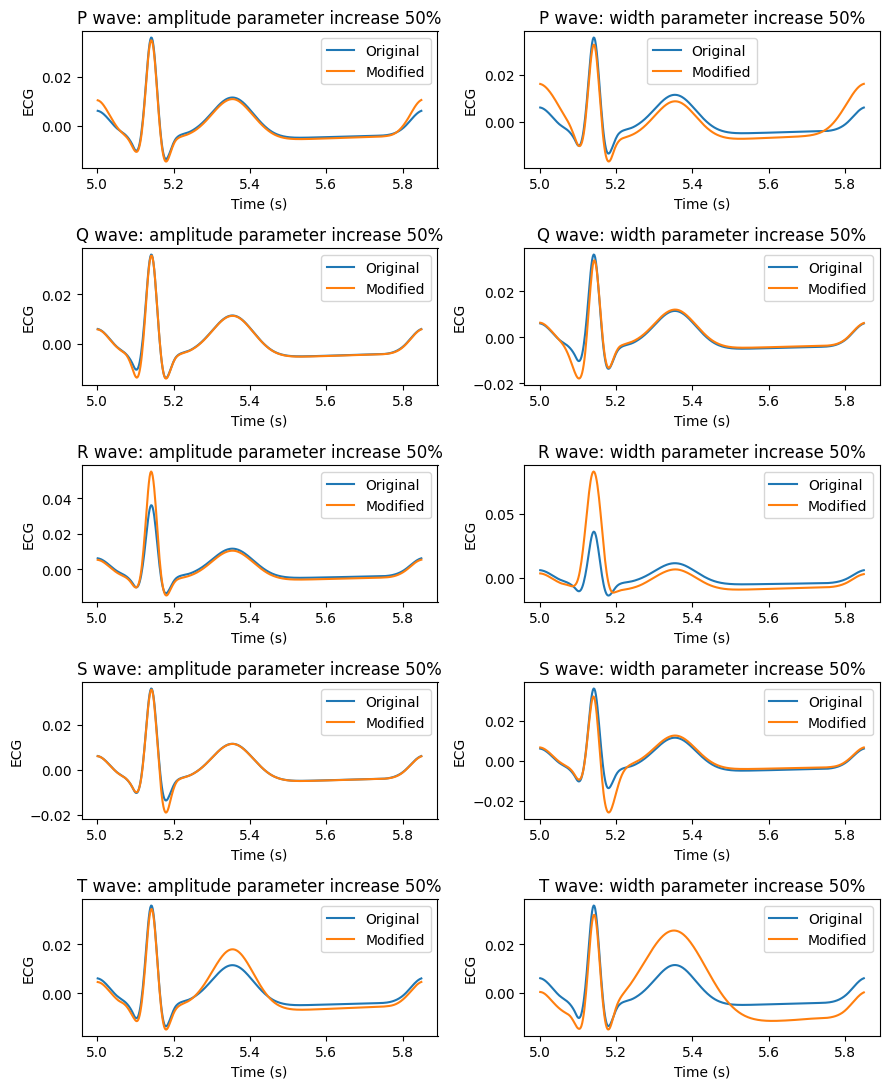

In [19]:
# Heart rate HR = 70
omega = 2 * np.pi * 70 / 60

# Original parameters (P, Q, R, S, T)
theta_i = np.array([-np.pi/3, -np.pi/12, 0, np.pi/12, np.pi/2])
a_original = np.array([1.2, -5, 30, -7.5, 0.75])
b_original = np.array([0.25, 0.1, 0.1, 0.1, 0.4])

# Differential equations
def ecg_model(t, state, a, b):
    x, y, z = state

    rho = 1 - np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)
    dtheta = (theta - theta_i + np.pi) % (2 * np.pi) - np.pi

    dx_dt = rho * x - omega * y
    dy_dt = rho * y + omega * x
    dz_dt = -np.sum(a * dtheta * np.exp(-dtheta**2 / (2 * b**2))) - z

    return [dx_dt, dy_dt, dz_dt]

# Generate ECG
t = np.linspace(0, 10, 5000)

def generate_ecg(a, b):
    solution = solve_ivp(
        ecg_model,
        (0, 10),
        [1, 0, 0],
        t_eval=t,
        args=(a, b)
    )
    return solution.y[2]

# Original ECG
z_original = generate_ecg(a_original, b_original)

# Plot one heartbeat after the initial transient for easy visualization
zoom = (t >= 5) & (t <= 5.85)

waves = ["P", "Q", "R", "S", "T"]
fig, axes = plt.subplots(5, 2, figsize=(9, 11))

for i, wave in enumerate(waves):

    # Change amplitude parameter only
    a_new = a_original.copy()
    a_new[i] *= 1.5
    z_a = generate_ecg(a_new, b_original)

    axes[i, 0].plot(t[zoom], z_original[zoom], label="Original")
    axes[i, 0].plot(t[zoom], z_a[zoom], label="Modified")
    axes[i, 0].set_title(f"{wave} wave: amplitude parameter increase 50%")
    axes[i, 0].set_xlabel("Time (s)")
    axes[i, 0].set_ylabel("ECG")
    axes[i, 0].legend()

    # Change width parameter only
    b_new = b_original.copy()
    b_new[i] *= 1.5
    z_b = generate_ecg(a_original, b_new)

    axes[i, 1].plot(t[zoom], z_original[zoom], label="Original")
    axes[i, 1].plot(t[zoom], z_b[zoom], label="Modified")
    axes[i, 1].set_title(f"{wave} wave: width parameter increase 50%")
    axes[i, 1].set_xlabel("Time (s)")
    axes[i, 1].set_ylabel("ECG")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()


## B(iii)

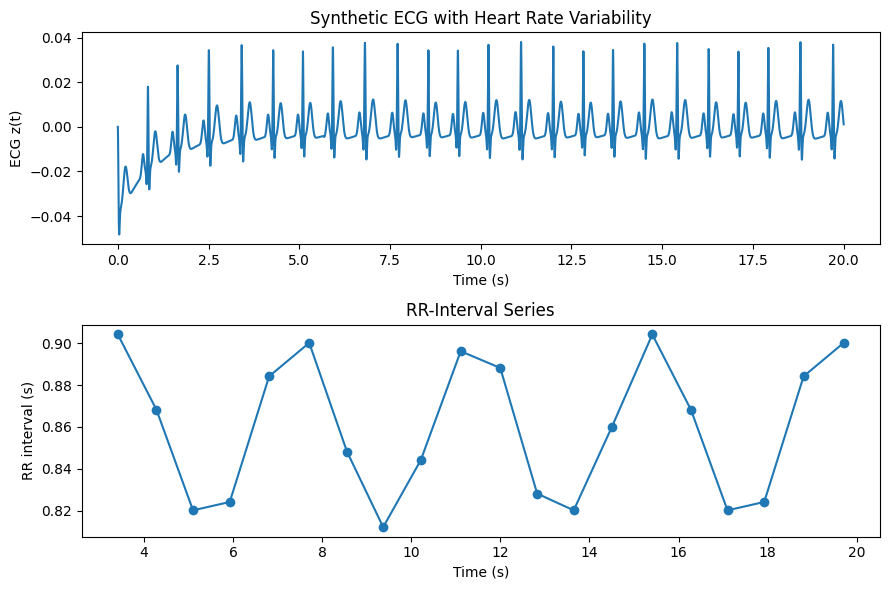

In [28]:
# Heart rate parameters
HR = 70
HRV = 4
f = 0.25

# Original McSharry-Clifford parameters (P, Q, R, S, T)
theta_i = np.array([-np.pi/3, -np.pi/12, 0, np.pi/12, np.pi/2])
a_i = np.array([1.2, -5, 30, -7.5, 0.75])
b_i = np.array([0.25, 0.1, 0.1, 0.1, 0.4])

# Differential equations
def ecg_model(t, state):
    x, y, z = state

    rho = 1 - np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)
    dtheta = (theta - theta_i + np.pi) % (2 * np.pi) - np.pi

    # Time-varying heart rate
    hr = HR + HRV * np.sin(2 * np.pi * f * t)
    omega = 2 * np.pi * hr / 60

    dx_dt = rho * x - omega * y
    dy_dt = rho * y + omega * x
    dz_dt = -np.sum(a_i * dtheta * np.exp(-dtheta**2 / (2 * b_i**2))) - z

    return [dx_dt, dy_dt, dz_dt]

# Simulate 20 seconds
t = np.linspace(0, 20, 5000)

solution = solve_ivp(
    ecg_model,
    (0, 20),
    [1, 0, 0],
    t_eval=t
)

z = solution.y[2]

# Detect R peaks
peaks, _ = find_peaks(z, distance=int(0.6 / (t[1] - t[0])))

# Remove initial transient
peaks = peaks[t[peaks] >= 2]

# Calculate RR intervals
r_times = t[peaks]
rr_intervals = np.diff(r_times)

fig, axes = plt.subplots(2, 1, figsize=(9, 6))

# Modified ECG
axes[0].plot(t, z)
axes[0].set_title("Synthetic ECG with Heart Rate Variability")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("ECG z(t)")

# RR intervals
axes[1].plot(r_times[1:], rr_intervals, marker="o")
axes[1].set_title("RR-Interval Series")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("RR interval (s)")

plt.tight_layout()
plt.show()


## C

Three codes are executed from the OSET library. The test_ecg_gen_noisy simulation generates multiple ECG channels with different waveform amplitudes. The added colored noise introduces irregular fluctuations, making some ECG components more difficult to identify. This demonstrates how measurement noise can affect ECG signal quality. The testStochasticECGDipoleGenerator simulation introduces random variations in heart rate and waveform parameters, including amplitude and width. The results show that the ECG maintains periodic structure, but the spacing and amplitude of individual heartbeats vary. Like what we did in B(iii), these variations make the signal less repetitive and better represent natural physiological changes. The test_ecg_gen_fetal_maternal1 simulation generates multichannel ECG signals containing maternal-fetal cardiac activity. The model specifies a maternal heart rate of 54 bpm and a fetal heart rate of 132 bpm. The prominent peaks appear approximately every 1.1 seconds shown in plot.

Stochastic modeling is important because real ECG recordings contain natural variations in heartbeat and measurement noise. Training machine learning models using perfectly repetitive synthetic signals may cause them to learn unrealistic patterns that do not generalize well to real patients. Introducing random parameter variations and realistic noise can increase data diversity and potentially improve model robustness.



